# 01 · Preparação dos dados: medições de ping do RIPE Atlas

**Objetivo deste notebook:** baixar as medições de ping que o grupo coletou no projeto integrador,
criar o alvo **"classe do fluxo daqui a 12 minutos"** e deixar treino, validação e teste prontos
para comparar Árvore de Decisão, Random Forest e XGBoost no próximo notebook.

**Por que estes dados?** Escolhemos o problema "previsão de falha ou congestionamento" da atividade.
Os dados são medições **públicas** de ping entre servidores (Anchors) do RIPE Atlas, que o grupo
coletou e rotulou no projeto
[Projeto-WebAgriculture-](https://github.com/ZorahSai/Projeto-WebAgriculture-) (Tarefas 1 e 2).

## 1. Instalar e importar as bibliotecas

In [1]:
# Instala tudo o que o projeto usa no MESMO Python do notebook (funciona no Colab e no computador)
%pip install -q pandas numpy scikit-learn xgboost matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

SEMENTE = 42          # semente fixa: todo mundo que rodar obtém os mesmos números
np.random.seed(SEMENTE)

# Pasta raiz do projeto: funciona rodando de dentro de notebooks/ ou no Colab
RAIZ = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
n = lambda v: f"{int(v):,}".replace(",", ".")   # número com ponto de milhar, como no Brasil
DADOS = os.path.join(RAIZ, "dados")
IMG = os.path.join(RAIZ, "img")
RESULTADOS = os.path.join(RAIZ, "resultados")
for pasta in (DADOS, IMG, RESULTADOS):
    os.makedirs(pasta, exist_ok=True)

# Versões das bibliotecas: copie essas linhas para o README e para a página
print("Python      ", sys.version.split()[0])
print("pandas      ", pd.__version__)
print("numpy       ", np.__version__)
print("scikit-learn", sklearn.__version__)

Python       3.14.7
pandas       3.0.6
numpy        2.5.4
scikit-learn 1.9.1


In [3]:
# Paleta visual do projeto (a mesma da página): Cotton, Cherry Red, Maroon, Noir Black e um neutro
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap

COTTON, CHERRY, MAROON, NOIR, NEUTRO = "#EDEBDD", "#810100", "#630000", "#1B1717", "#8C8475"
AREIA = "#C9BFA8"     # cor extra para a persistência (a regra de comparação)
FUNDO = "#F6F4EA"     # fundo das figuras, igual ao das caixas da página

plt.rcParams.update({
    "axes.prop_cycle": cycler(color=[CHERRY, NOIR, NEUTRO, AREIA]),   # Árvore, Random Forest, XGBoost, persistência
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "savefig.facecolor": FUNDO,
    "axes.edgecolor": NOIR, "axes.labelcolor": NOIR, "text.color": NOIR,
    "xtick.color": NOIR, "ytick.color": NOIR, "grid.color": "#D8D3C2",
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
})
MAPA_CONFUSAO = LinearSegmentedColormap.from_list("cotton_maroon", [COTTON, "#DDA59C", "#A8322B", MAROON])
CORES_CLASSE = {"OK": "#4F6F52", "RISCO": "#B8860B", "FALHA": CHERRY}

## 2. De onde vêm os dados

O RIPE Atlas é uma rede de sondas que medem a internet e publicam os resultados. Entre os servidores
mais estáveis dessa rede (as **Anchors**), há pings automáticos a cada 240 segundos, com 3 pacotes por vez.

No projeto integrador, o grupo:

1. Baixou 14 dias de medições de **97 fluxos** (um fluxo é o par sonda de origem → servidor de destino),
   com caminhos de 1 ms a 318 ms (**Tarefa 1**).
2. Usou a primeira semana (Período A) só para aprender o **normal de cada fluxo**: a mediana do RTT e o quanto ele costuma variar (MAD).
3. Rotulou cada medição da segunda semana (Período B) como **OK**, **RISCO** ou **FALHA**, comparando com o normal
   do próprio fluxo, e dividiu o Período B no tempo em treino, validação e teste (**Tarefa 2**).

O arquivo rotulado está no repositório do projeto. Este notebook baixa esse arquivo direto do GitHub.

In [4]:
URL_DATASET = ("https://raw.githubusercontent.com/ZorahSai/Projeto-WebAgriculture-/main/"
               "data/processed/dataset_rotulado_B.csv.gz")
CAMINHO_LOCAL = None   # ou o caminho do arquivo, se você já tiver baixado o repositório do projeto

bruto = pd.read_csv(CAMINHO_LOCAL or URL_DATASET, parse_dates=["timestamp"])
print(f"{n(len(bruto))} medições do Período B, {bruto['fluxo_id'].nunique()} fluxos")

230.854 medições do Período B, 92 fluxos


## 3. Tirar os endereços IP antes de qualquer coisa

O arquivo do projeto identifica cada fluxo por `probe_id|IP do destino`. Os IPs são de servidores públicos
do RIPE Atlas, mas a atividade pede para **nunca publicar endereços IP reais**. Por isso:

- cada fluxo vira um código anônimo (`F01`, `F02`, ...), ordenado pelo RTT normal;
- as colunas com IP e com o identificador da sonda saem da tabela;
- ficam só o nome curto do destino e o país de origem, que usamos para descrever caminhos curtos e longos.

In [5]:
medianas = bruto.groupby("fluxo_id")["mediana"].first().sort_values()
codigo = {fluxo: f"F{i:02d}" for i, fluxo in enumerate(medianas.index, 1)}

dados = bruto.assign(
    fluxo=bruto["fluxo_id"].map(codigo),
    destino=bruto["destino_fqdn"].str.split("-").str[:2].str.join("-"),   # ex.: "jp-tch"
).drop(columns=["fluxo_id", "dst_addr", "probe_id", "destino_fqdn"])

assert not dados.astype(str).apply(lambda c: c.str.contains(r"\d+\.\d+\.\d+\.\d+")).any().any(), "Sobrou IP!"
dados[["timestamp", "fluxo", "destino", "pais_origem", "mediana", "latencia_ms", "z_robusto", "classe"]].head()

,timestamp,fluxo,destino,pais_origem,mediana,latencia_ms,z_robusto,classe
0,2026-09-13 04:33:08+00:00,F21,de-mdt,LV,33.67,33.749,0.592053,OK
1,2026-09-13 04:37:06+00:00,F21,de-mdt,LV,33.67,33.668,-0.014989,OK
2,2026-09-13 04:41:13+00:00,F21,de-mdt,LV,33.67,33.525,-1.086680,OK
3,2026-09-13 04:45:06+00:00,F21,de-mdt,LV,33.67,34.137,3.499860,OK
4,2026-09-13 04:49:18+00:00,F21,de-mdt,LV,33.67,34.494,6.175340,FALHA


## 4. O que tem em cada linha

Cada linha é **uma medição de ping de um fluxo**. As colunas que os modelos vão usar comparam a medição
com o normal daquele fluxo. Nenhuma delas é o RTT em milissegundos: no projeto, o RTT absoluto é proibido
como atributo, porque um RTT alto pode ser só um caminho longo e saudável.

| Atributo | O que mede |
|---|---|
| `z_robusto` | quantos "desvios típicos" o RTT de agora está acima do normal do fluxo |
| `aumento_pct` | quanto o RTT subiu em relação ao normal, em % |
| `jitter_relativo` | variação do RTT agora dividida pela variação típica do fluxo |
| `perda_pct` | pacotes perdidos nesta medição (0, 33, 67 ou 100%) |
| `timeout_atual` | 1 se nenhum pacote voltou |
| `n5_timeout`, `n5_aumento80`, `n5_risco` | nas últimas 5 medições: timeouts, aumentos acima de 80% e desvios moderados |

`classe` é o estado **atual** do fluxo, dado pela regra do projeto. Valores vazios significam "não havia RTT"
(por exemplo, num timeout) e ficam vazios: os três modelos sabem lidar com eles.

## 5. Criar o alvo: o estado do fluxo daqui a 12 minutos

A pergunta do artigo é de **previsão**: olhando a medição de agora, qual será a classe do fluxo **3 medições depois**
(3 × 240 s = 12 minutos)?

Regras para não trapacear:

- o futuro é sempre do **mesmo fluxo**;
- só aceitamos o par se a medição futura estiver mesmo a ~12 minutos (entre 11 e 13 minutos); lacunas na coleta ficam de fora;
- a medição de agora e a futura têm de estar no **mesmo bloco** (treino, validação ou teste) do projeto. Assim, nenhum rótulo da validação ou do teste vaza para o treino.

In [6]:
PASSOS = 3                      # 3 medições à frente
JANELA_S = (660, 780)           # 11 a 13 minutos

dados = dados.sort_values(["fluxo", "timestamp"]).reset_index(drop=True)
grupo = dados.groupby("fluxo")
dados["classe_futura"] = grupo["classe"].shift(-PASSOS)
dados["bloco_futuro"] = grupo["bloco"].shift(-PASSOS)
dados["segundos_ate_futuro"] = (grupo["timestamp"].shift(-PASSOS) - dados["timestamp"]).dt.total_seconds()

valido = (
    dados["classe_futura"].notna()
    & dados["segundos_ate_futuro"].between(*JANELA_S)
    & (dados["bloco"] == dados["bloco_futuro"])
    & dados["bloco"].isin(["treino", "validacao", "teste"])   # as linhas de "embargo" do projeto ficam fora
)
print(f"Pares válidos: {n(valido.sum())} de {n(len(dados))}")
dados = dados[valido].rename(columns={"classe": "classe_atual"}).reset_index(drop=True)

Pares válidos: 227.112 de 230.854


## 6. Quão desbalanceadas são as classes?

A maior parte do tempo a rede está no próprio normal. É isso que torna a acurácia enganosa:
um modelo que sempre diz OK acerta quase 80% e não serve para nada.

In [7]:
ORDEM_BLOCOS = ["treino", "validacao", "teste"]
CLASSES = ["OK", "RISCO", "FALHA"]

resumo = (dados.groupby("bloco")["classe_futura"].value_counts(normalize=True)
          .unstack().reindex(index=ORDEM_BLOCOS, columns=CLASSES) * 100).round(2)
resumo["linhas"] = dados["bloco"].value_counts().reindex(ORDEM_BLOCOS)
resumo

classe_futura,OK,RISCO,FALHA,linhas
bloco,,,,
treino,82.52,6.52,10.97,115183
validacao,78.12,8.09,13.79,45227
teste,78.06,7.60,14.34,66702


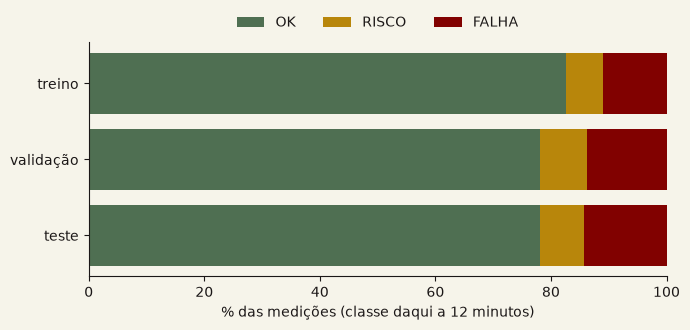

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.4))
esquerda = np.zeros(len(ORDEM_BLOCOS))
for c in CLASSES:
    ax.barh(["treino", "validação", "teste"], resumo[c], left=esquerda, color=CORES_CLASSE[c], label=c)
    esquerda += resumo[c].values
ax.set_xlabel("% das medições (classe daqui a 12 minutos)")
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(IMG, "distribuicao_classes.png"), dpi=150)
plt.show()

## 7. A régua que todo modelo precisa vencer: a persistência

A previsão mais simples possível é **repetir a classe de agora**: "se está OK, daqui a 12 minutos vai estar OK".
Chamamos isso de **persistência**. Ela acerta sempre que nada muda e erra **toda** mudança de estado.
Um modelo só serve como *preditor* se fizer melhor que ela, principalmente nas mudanças.

In [9]:
mudou = dados["classe_atual"] != dados["classe_futura"]
inicio_falha = (dados["classe_futura"] == "FALHA") & (dados["classe_atual"] != "FALHA")
print(f"A classe muda em 12 minutos em {mudou.mean():.1%} das medições.")
print(f"Inícios de FALHA (agora não é FALHA, daqui a 12 min é): {n(inicio_falha.sum())}")
pd.crosstab(dados["classe_atual"], dados["classe_futura"]).reindex(index=CLASSES, columns=CLASSES)

A classe muda em 12 minutos em 13.5% das medições.
Inícios de FALHA (agora não é FALHA, daqui a 12 min é): 8.186


classe_futura,OK,RISCO,FALHA
classe_atual,,,
OK,168389,7011,7087
RISCO,7253,7845,1099
FALHA,6804,1377,20247


## 8. Caminhos curtos, regionais e longos

Para conferir que nenhum modelo aprende a "geografia", separamos os fluxos em três grupos pelo RTT normal (tercis da mediana do Período A).
Essa coluna **não** entra nos modelos: serve só para analisar os erros depois.

In [10]:
mediana_fluxo = dados.groupby("fluxo")["mediana"].first()
escopo = pd.qcut(mediana_fluxo, 3, labels=["curto", "regional", "longo"])
dados["escopo"] = dados["fluxo"].map(escopo).astype(str)
print(mediana_fluxo.groupby(escopo, observed=True).agg(["count", "min", "max"]).round(1))

          count    min    max
mediana                      
curto        31    1.0   42.1
regional     30   42.7  106.9
longo        31  108.1  315.1


## 9. Salvar os dados prontos para o próximo notebook

Salvamos em `dados/` (essa pasta está no `.gitignore`: o arquivo é refeito por este notebook, não precisa subir para o GitHub).

In [11]:
ATRIBUTOS = ["z_robusto", "aumento_pct", "jitter_relativo", "perda_pct", "timeout_atual",
             "n5_timeout", "n5_aumento80", "n5_risco"]
colunas = ["timestamp", "fluxo", "destino", "pais_origem", "escopo", "bloco", "mediana", "latencia_ms",
           *ATRIBUTOS, "classe_atual", "classe_futura"]
dados[colunas].to_csv(os.path.join(DADOS, "dataset_artigo.csv.gz"), index=False)
print("Salvo em dados/dataset_artigo.csv.gz")
print(dados["bloco"].value_counts().reindex(ORDEM_BLOCOS))

Salvo em dados/dataset_artigo.csv.gz
bloco
treino       115183
validacao     45227
teste         66702
Name: count, dtype: int64


## Próximo passo

No notebook `02_modelos.ipynb` treinamos a **Árvore de Decisão**, a **Random Forest** e o **XGBoost** com o mesmo
esforço de ajuste e comparamos com a **persistência**: F1 macro, recall de FALHA, inícios de FALHA, matriz de confusão e tempo.